# CatBoost model

A full 20-combination depth/learning-rate/L2 grid search on the same 35 features, followed by feature ablations. Select tree count inside an earlier chronological split and refit the entire outer training window. Native categorical handling is used.

Run notebooks 06–10 in order. Existing notebooks 01–05 and processed datasets are read-only inputs. Results are written to `experiments/results/`. Scores use individual rents in SGD; tuning folds are July–December 2023 and January–June 2024. No final-block scores are used in model or feature selection.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / "data/train.csv").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from experiments import rental_experiments as exp


## Model configuration

The full grid crosses depths [6, 8], learning rates [0.001, 0.005, 0.01, 0.05, 0.08], and L2 regularization [3, 5], including both previously tested configurations. Each of the 20 combinations is evaluated on both earlier chronological folds; the lowest mean RMSE selects parameters before feature ablations. All use RMSE loss, seed 42, four CPU threads, chronological input order, and at most 500 trees. This fixed budget may disadvantage low learning rates that need more trees. The last three training months select tree count, with 40-round early stopping; a fresh model then fits the complete outer training window.

Categorical columns are passed directly to CatBoost, and numeric missing values use its native handling. After choosing parameters on the base features, evaluate schools, malls, both, and past rental summaries. No final evaluation targets participate in selection.

The shared implementation and optional configuration arguments are in `experiments/rental_experiments.py`.

In [2]:
scores = exp.model_experiment("catboost")
display(scores)
display(scores.groupby(["group", "params"])[["RMSE", "MAE", "seconds"]].mean())

catboost keep_all block_recovery base {'depth': 6, 'l2_leaf_reg': 3, 'learning_rate': 0.001} 2023_H2: RMSE=786.437; 26.5s


catboost keep_all block_recovery base {'depth': 6, 'l2_leaf_reg': 3, 'learning_rate': 0.001} 2024_H1: RMSE=687.158; 32.2s


catboost keep_all block_recovery base {'depth': 6, 'l2_leaf_reg': 3, 'learning_rate': 0.005} 2023_H2: RMSE=602.940; 28.2s


catboost keep_all block_recovery base {'depth': 6, 'l2_leaf_reg': 3, 'learning_rate': 0.005} 2024_H1: RMSE=532.974; 33.5s


catboost keep_all block_recovery base {'depth': 6, 'l2_leaf_reg': 3, 'learning_rate': 0.01} 2023_H2: RMSE=585.469; 30.2s


catboost keep_all block_recovery base {'depth': 6, 'l2_leaf_reg': 3, 'learning_rate': 0.01} 2024_H1: RMSE=523.610; 35.3s


... (40 outputs left out)

catboost keep_all block_recovery history {'depth': 8, 'l2_leaf_reg': 3, 'learning_rate': 0.05} 2023_H2: RMSE=576.844; 33.8s


catboost keep_all block_recovery history {'depth': 8, 'l2_leaf_reg': 3, 'learning_rate': 0.05} 2024_H1: RMSE=516.121; 35.9s


,model,policy,imputation,group,params,fold,RMSE,MAE,bias_actual_minus_predicted,selected_iterations,train_rows,evaluation_rows,seconds
0,catboost,keep_all,block_recovery,base,"{""depth"": 6, ""l2_leaf_reg"": 3, ""learning_rate""...",2023_H2,786.436872,645.661668,415.456064,500,87937,17900,26.505710
1,catboost,keep_all,block_recovery,base,"{""depth"": 6, ""l2_leaf_reg"": 3, ""learning_rate""...",2024_H1,687.158067,561.108188,320.512290,500,105837,18179,32.152388
2,catboost,keep_all,block_recovery,base,"{""depth"": 6, ""l2_leaf_reg"": 3, ""learning_rate""...",2023_H2,602.939989,483.460181,87.941567,500,87937,17900,28.161218
3,catboost,keep_all,block_recovery,base,"{""depth"": 6, ""l2_leaf_reg"": 3, ""learning_rate""...",2024_H1,532.973537,404.352924,10.663777,500,105837,18179,33.515794
4,catboost,keep_all,block_recovery,base,"{""depth"": 6, ""l2_leaf_reg"": 3, ""learning_rate""...",2023_H2,585.468739,462.853329,24.434726,500,87937,17900,30.204973
5,catboost,keep_all,block_recovery,base,"{""depth"": 6, ""l2_leaf_reg"": 3, ""learning_rate""...",2024_H1,523.610358,388.752181,-43.510282,500,105837,18179,35.267617
6,catboost,keep_all,block_recovery,base,"{""depth"": 6, ""l2_leaf_reg"": 3, ""learning_rate""...",2023_H2,578.449837,455.977645,10.850162,353,87937,17900,24.282556
7,catboost,keep_all,block_recovery,base,"{""depth"": 6, ""l2_leaf_reg"": 3, ""learning_rate""...",2024_H1,516.883449,382.857202,-49.253003,489,105837,18179,37.616367
8,catboost,keep_all,block_recovery,base,"{""depth"": 6, ""l2_leaf_reg"": 3, ""learning_rate""...",2023_H2,581.134560,461.468652,36.825906,249,87937,17900,17.889889
9,catboost,keep_all,block_recovery,base,"{""depth"": 6, ""l2_leaf_reg"": 3, ""learning_rate""...",2024_H1,517.112420,383.094302,-46.833075,373,105837,18179,29.838224


RMSE  \
group         params                                                           
base          {"depth": 6, "l2_leaf_reg": 3, "learning_rate":...  736.797470   
              {"depth": 6, "l2_leaf_reg": 3, "learning_rate":...  567.956763   
              {"depth": 6, "l2_leaf_reg": 3, "learning_rate":...  554.539548   
              {"depth": 6, "l2_leaf_reg": 3, "learning_rate":...  547.666643   
              {"depth": 6, "l2_leaf_reg": 3, "learning_rate":...  549.123490   
              {"depth": 6, "l2_leaf_reg": 5, "learning_rate":...  736.555022   
              {"depth": 6, "l2_leaf_reg": 5, "learning_rate":...  567.502933   
              {"depth": 6, "l2_leaf_reg": 5, "learning_rate":...  554.739243   
              {"depth": 6, "l2_leaf_reg": 5, "learning_rate":...  547.422957   
              {"depth": 6, "l2_leaf_reg": 5, "learning_rate":...  548.450047   
              {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  730.284712   
              {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  563.660735   
              {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  551.719153   
              {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  547.371836   
              {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  548.658561   
              {"depth": 8, "l2_leaf_reg": 5, "learning_rate":...  730.623740   
              {"depth": 8, "l2_leaf_reg": 5, "learning_rate":...  564.564514   
              {"depth": 8, "l2_leaf_reg": 5, "learning_rate":...  552.521081   
              {"depth": 8, "l2_leaf_reg": 5, "learning_rate":...  548.041824   
              {"depth": 8, "l2_leaf_reg": 5, "learning_rate":...  548.066593   
history       {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  546.482428   
malls         {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  547.652754   
schools       {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  548.135314   
schools_malls {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  546.985166   

                                                                         MAE  \
group         params                                                           
base          {"depth": 6, "l2_leaf_reg": 3, "learning_rate":...  603.384928   
              {"depth": 6, "l2_leaf_reg": 3, "learning_rate":...  443.906553   
              {"depth": 6, "l2_leaf_reg": 3, "learning_rate":...  425.802755   
              {"depth": 6, "l2_leaf_reg": 3, "learning_rate":...  419.417424   
              {"depth": 6, "l2_leaf_reg": 3, "learning_rate":...  422.281477   
              {"depth": 6, "l2_leaf_reg": 5, "learning_rate":...  603.154692   
              {"depth": 6, "l2_leaf_reg": 5, "learning_rate":...  443.446847   
              {"depth": 6, "l2_leaf_reg": 5, "learning_rate":...  425.997226   
              {"depth": 6, "l2_leaf_reg": 5, "learning_rate":...  419.444754   
              {"depth": 6, "l2_leaf_reg": 5, "learning_rate":...  420.441184   
              {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  598.366697   
              {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  440.272075   
              {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  423.203792   
              {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  419.803990   
              {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  419.939641   
              {"depth": 8, "l2_leaf_reg": 5, "learning_rate":...  598.425717   
              {"depth": 8, "l2_leaf_reg": 5, "learning_rate":...  441.121531   
              {"depth": 8, "l2_leaf_reg": 5, "learning_rate":...  424.057895   
              {"depth": 8, "l2_leaf_reg": 5, "learning_rate":...  419.782639   
              {"depth": 8, "l2_leaf_reg": 5, "learning_rate":...  419.334678   
history       {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  417.479021   
malls         {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  420.312810   
schools       {"depth": 8, "l2_leaf_reg": 3, "learning_rate":...  419.8

In [3]:
import json
display(json.loads((exp.OUT / "catboost_selection.json").read_text()))

{'model': 'catboost',
 'params': {'depth': 8, 'l2_leaf_reg': 3, 'learning_rate': 0.05},
 'group': 'base',
 'policy': 'keep_all',
 'imputation': 'block_recovery',
 'mean_RMSE': 547.3718358942915,
 'feature_selection_rule': 'Minimum earlier-fold mean RMSE; retain base if improvement <1 SGD.',
 'seed_policy': 'MLP uses predeclared seed 42; other seeds are stability diagnostics.'}

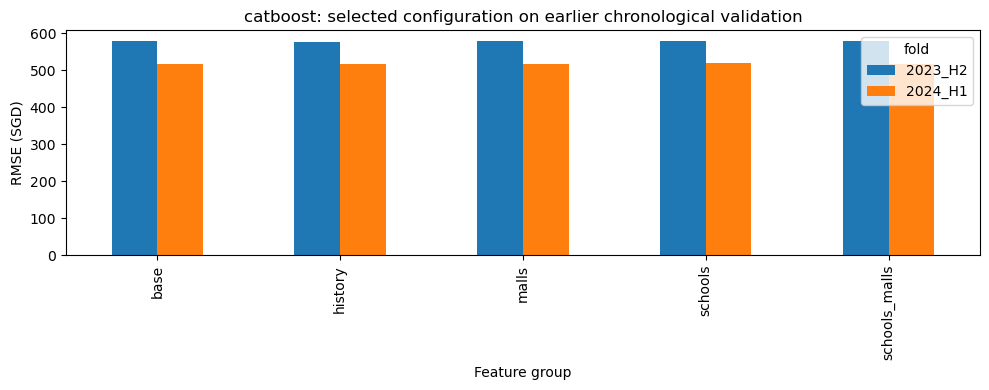

In [4]:
selected = json.loads((exp.OUT / "catboost_selection.json").read_text())
fixed = scores[scores.params.eq(json.dumps(selected["params"], sort_keys=True))]
summary = fixed.groupby(["group", "fold"]).RMSE.mean().unstack("fold")
summary.plot.bar(figsize=(10, 4))
plt.ylabel("RMSE (SGD)")
plt.xlabel("Feature group")
plt.title("catboost: selected configuration on earlier chronological validation")
plt.tight_layout()
plt.show()

## Interpretation

Read per-fold scores before interpreting the mean. A lower score does not establish causality. Explain temporal drift, duplicate uncertainty, snapshot limitations, and computational cost in the report. Hyperparameters and selections are saved alongside results.

References: [CatBoost fit API](https://catboost.ai/docs/en/concepts/python-reference_catboostregressor_fit); [scikit-learn MLPRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html).